In [ ]:
!pip install -q kagglehub

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from pathlib import Path
from PIL import Image

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
dataset_path = kagglehub.dataset_download(
    "bhavikjikadara/dog-and-cat-classification-dataset"
)

print("Dataset Path:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    print(root, "->", len(files), "files")
    if root.count(os.sep) - dataset_path.count(os.sep) >= 2:
        dirs[:] = []


Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Dataset Path: /kaggle/input/dog-and-cat-classification-dataset
/kaggle/input/dog-and-cat-classification-dataset -> 0 files
/kaggle/input/dog-and-cat-classification-dataset/PetImages -> 0 files
/kaggle/input/dog-and-cat-classification-dataset/PetImages/Dog -> 12499 files
/kaggle/input/dog-and-cat-classification-dataset/PetImages/Cat -> 12499 files


In [ ]:
DATASET_DIR = Path(dataset_path)
from collections import Counter

DATA_DIR = DATASET_DIR / "PetImages"

classes = ["Cat", "Dog"]

corrupted_images = []
image_dimensions = Counter()
image_formats = Counter()

for class_name in classes:

    class_dir = DATA_DIR / class_name

    for image_path in class_dir.iterdir():

        if not image_path.is_file():
            continue

        try:
            with Image.open(image_path) as img:

                img.verify()

            with Image.open(image_path) as img:

                image_dimensions[img.size] += 1
                image_formats[img.format] += 1

        except Exception:
            corrupted_images.append(str(image_path))

print("IMAGE INTEGRITY REPORT")
print("=" * 45)

print("Total corrupted images:", len(corrupted_images))
print("Valid images:", sum(image_dimensions.values()))

print("\nImage Formats:")
for fmt, count in image_formats.most_common():
    print(f"{fmt}: {count}")

print("\nMost Common Image Dimensions:")
for dimension, count in image_dimensions.most_common(10):
    print(f"{dimension}: {count}")


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


IMAGE INTEGRITY REPORT
Total corrupted images: 0
Valid images: 24998

Image Formats:
JPEG: 24769
BMP: 173
GIF: 51
PNG: 4
PSD: 1

Most Common Image Dimensions:
(500, 375): 5867
(375, 500): 488
(500, 333): 427
(320, 240): 399
(500, 374): 189
(500, 332): 183
(350, 262): 181
(400, 300): 164
(480, 360): 138
(500, 500): 133


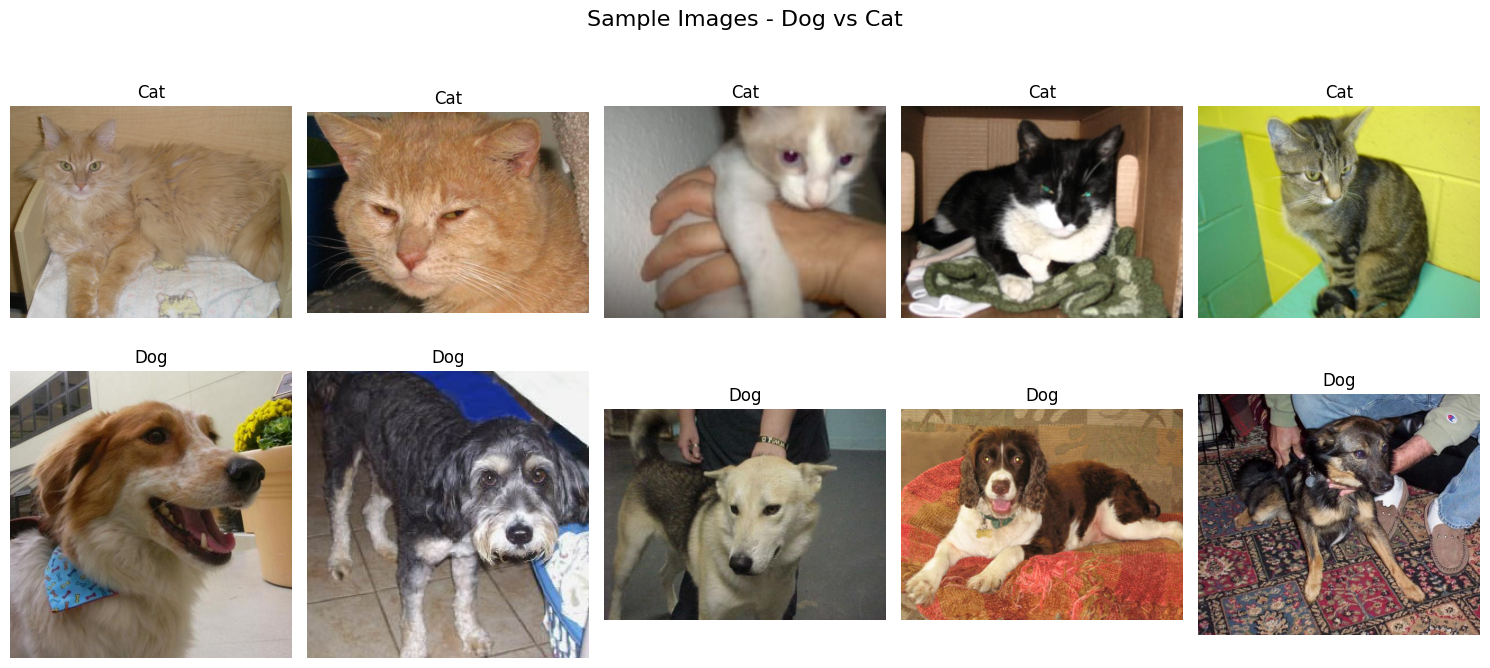

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, class_name in enumerate(classes):

    class_dir = DATA_DIR / class_name

    image_paths = list(class_dir.glob("*.jpg"))

    selected_images = np.random.choice(
        image_paths,
        size=5,
        replace=False
    )

    for col, image_path in enumerate(selected_images):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Sample Images - Dog vs Cat", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = DATASET_DIR / "PetImages"

classes = ["Cat", "Dog"]
IMAGE_EXTENSIONS = {
    '.jpg',
    '.jpeg',
    '.png',
    '.bmp',
    '.webp',
    '.gif',
    '.psd'
}

image_paths = []
labels = []

for class_name in classes:

    class_dir = DATA_DIR / class_name

    for image_path in class_dir.iterdir():

        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:

            image_paths.append(str(image_path))
            labels.append(0 if class_name == "Cat" else 1)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print("Total Images:", len(df))
print("\nClass Distribution:")
print(df["label"].value_counts().sort_index())

print("\nLabel Mapping:")
print("0 = Cat")
print("1 = Dog")

df.head()

Total Images: 24998

Class Distribution:
label
0    12499
1    12499
Name: count, dtype: int64

Label Mapping:
0 = Cat
1 = Dog


,filepath,label
0,/kaggle/input/dog-and-cat-classification-datas...,0
1,/kaggle/input/dog-and-cat-classification-datas...,0
2,/kaggle/input/dog-and-cat-classification-datas...,0
3,/kaggle/input/dog-and-cat-classification-datas...,0
4,/kaggle/input/dog-and-cat-classification-datas...,0


In [ ]:
# First split: 80% Train, 20% Temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

# Second split: 10% Validation, 10% Test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("DATASET SPLIT SUMMARY")
print("=" * 40)

print(f"Training Images:   {len(train_df)}")
print(f"Validation Images: {len(val_df)}")
print(f"Testing Images:    {len(test_df)}")

print("\nTraining Distribution:")
print(train_df["label"].value_counts())

print("\nValidation Distribution:")
print(val_df["label"].value_counts())

print("\nTesting Distribution:")
print(test_df["label"].value_counts())

DATASET SPLIT SUMMARY
Training Images:   19998
Validation Images: 2500
Testing Images:    2500

Training Distribution:
label
0    9999
1    9999
Name: count, dtype: int64

Validation Distribution:
label
1    1250
0    1250
Name: count, dtype: int64

Testing Distribution:
label
1    1250
0    1250
Name: count, dtype: int64


In [ ]:
import tensorflow as tf
import numpy as np
from PIL import Image

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess_image(filepath, label):

    def load_image(path):
        # path is a tf.Tensor; retrieve its numpy bytes value before decoding
        path_str = path.numpy().decode("utf-8")

        with Image.open(path_str) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE)
            image = np.asarray(img, dtype=np.float32)
            image = image / 255.0
            return image

    image = tf.py_function(
        load_image,
        [filepath],
        Tout=tf.float32
    )

    image.set_shape((128, 128, 3))
    label = tf.cast(label, tf.float32)

    return image, label


def create_dataset(dataframe, shuffle=False):

    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["filepath"].values,
        dataframe["label"].values
    ))

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=2000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Preprocessing pipelines created successfully!")

Preprocessing pipelines created successfully!


Image Batch Shape: (32, 128, 128, 3)
Label Batch Shape: (32,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Image Data Type: <dtype: 'float32'>


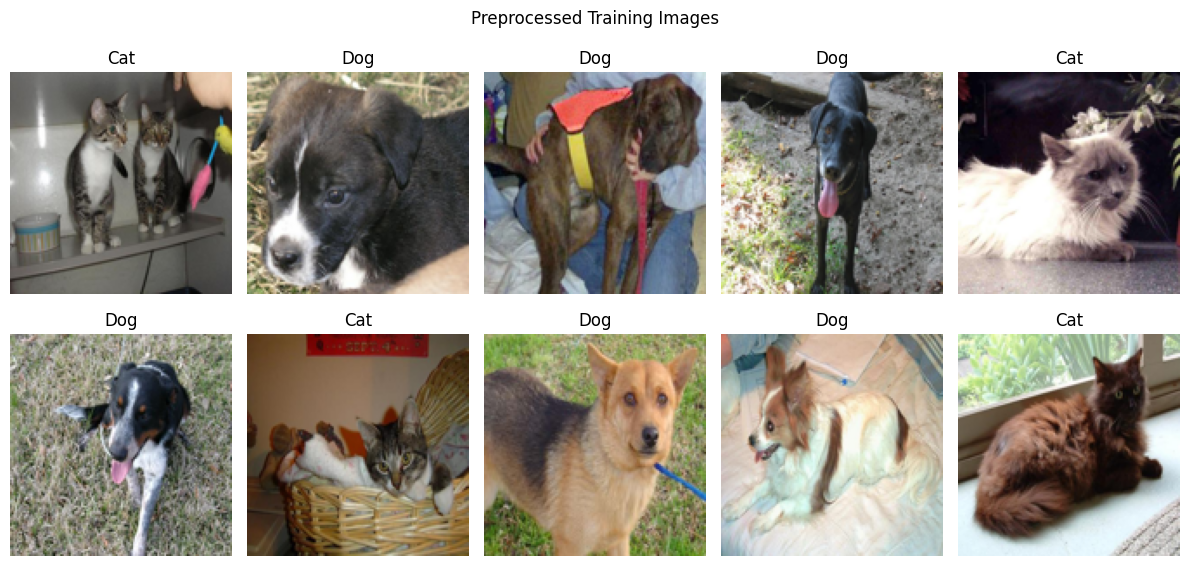

In [ ]:
images, labels = next(iter(train_ds))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)

print("Minimum Pixel Value:", tf.reduce_min(images).numpy())
print("Maximum Pixel Value:", tf.reduce_max(images).numpy())

print("Image Data Type:", images.dtype)

# Visualize preprocessed samples

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].numpy())

    label = int(labels[i].numpy())

    plt.title("Dog" if label == 1 else "Cat")
    plt.axis("off")

plt.suptitle("Preprocessed Training Images")
plt.tight_layout()
plt.show()

Step 3

In [ ]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.08
    ),

    tf.keras.layers.RandomZoom(
        0.10
    ),

    tf.keras.layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08
    ),

    tf.keras.layers.RandomContrast(
        0.10
    )

], name="data_augmentation")

print("Data Augmentation Pipeline Created!")
data_augmentation.summary()

Data Augmentation Pipeline Created!


Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ ?                      │   0 (unbuilt) │
│ (RandomContrast)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras import layers, models

INPUT_SHAPE = (128, 128, 3)

def conv_block(x, filters, dropout_rate):

    # First Convolution
    x = layers.Conv2D(
        filters,
        kernel_size=(3, 3),
        padding="same",
        kernel_initializer="he_normal",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # Second Convolution
    x = layers.Conv2D(
        filters,
        kernel_size=(3, 3),
        padding="same",
        kernel_initializer="he_normal",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # Downsampling
    x = layers.MaxPooling2D(
        pool_size=(2, 2)
    )(x)

    x = layers.Dropout(dropout_rate)(x)

    return x


# Input
inputs = layers.Input(shape=INPUT_SHAPE)

# Data Augmentation
x = data_augmentation(inputs)

# Normalize input is already done in preprocessing
# Convolution Blocks
x = conv_block(x, 32, 0.15)
x = conv_block(x, 64, 0.20)
x = conv_block(x, 128, 0.25)

# Feature Aggregation
x = layers.GlobalAveragePooling2D()(x)

# Fully Connected Layer
x = layers.Dense(
    128,
    activation="relu",
    kernel_initializer="he_normal"
)(x)

x = layers.Dropout(0.5)(x)

# Binary Classification Output
outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

# Build Model
model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="Dog_Cat_CNN"
)


In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Model Compiled Successfully!")


Model Compiled Successfully!


In [ ]:
model.summary()

print("\nTotal Parameters:",
      f"{model.count_params():,}")

print("Input Shape:", model.input_shape)
print("Output Shape:", model.output_shape)


Model: "Dog_Cat_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 304,993 (1.16 MB)

 Trainable params: 304,097 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)


Total Parameters: 304,993
Input Shape: (None, 128, 128, 3)
Output Shape: (None, 1)


Step 4

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath="best_dog_cat_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


In [ ]:
EPOCHS = 30

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1
)

print("\nTraining Completed!")

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.6022 - auc: 0.6358 - loss: 0.6869 - precision: 0.6038 - recall: 0.5690

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Epoch 1: val_loss improved from None to 0.59719, saving model to best_dog_cat_cnn.keras

Epoch 1: finished saving model to best_dog_cat_cnn.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 155s 215ms/step - accuracy: 0.6238 - auc: 0.6687 - loss: 0.6524 - precision: 0.6318 - recall: 0.5932 - val_accuracy: 0.6880 - val_auc: 0.7483 - val_loss: 0.5972 - val_precision: 0.6985 - val_recall: 0.6616 - learning_rate: 0.0010
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.6653 - auc: 0.7243 - loss: 0.6111 - precision: 0.6767 - recall: 0.6311
Epoch 2: val_loss did not improve from 0.59719
625/625 ━━━━━━━━━━━━━━━━━━━━ 138s 209ms/step - accuracy: 0.6757 - auc: 0.7357 - loss: 0.6037 - precision: 0.6878 - recall: 0.6436 - val_accuracy: 0.6668 - val_auc: 0.7816 - val_loss: 0.6067 - val_precision: 0.8390 - val_recall: 0.4128 - learning_rate: 0.0010
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.7052 - auc: 0.7703 - loss: 0.5738 - precision: 0.7148 - recall: 0.6748
Epoch 3: v

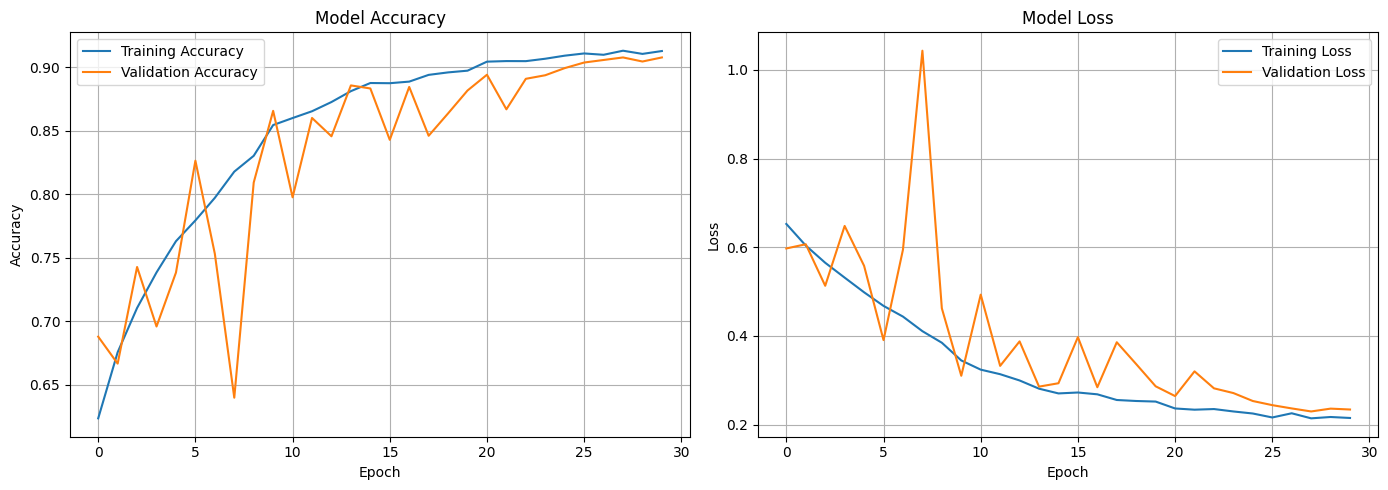

In [ ]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
best_epoch = np.argmin(history.history["val_loss"])

print("BEST TRAINING RESULTS")
print("=" * 40)

print("Best Epoch:", best_epoch + 1)

print(
    "Training Accuracy:",
    round(history.history["accuracy"][best_epoch], 4)
)

print(
    "Validation Accuracy:",
    round(history.history["val_accuracy"][best_epoch], 4)
)

print(
    "Validation Loss:",
    round(history.history["val_loss"][best_epoch], 4)
)

print(
    "Validation AUC:",
    round(history.history["val_auc"][best_epoch], 4)
)


BEST TRAINING RESULTS
Best Epoch: 28
Training Accuracy: 0.9129
Validation Accuracy: 0.9076
Validation Loss: 0.2297
Validation AUC: 0.9679


In [ ]:
best_model = tf.keras.models.load_model(
    "best_dog_cat_cnn.keras"
)

print("Best CNN Model Loaded Successfully!")
print("Model Name:", best_model.name)

Best CNN Model Loaded Successfully!
Model Name: Dog_Cat_CNN


In [ ]:
test_results = best_model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\nFINAL TEST RESULTS")
print("=" * 45)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.9020 - auc: 0.9663 - loss: 0.2370 - precision: 0.8954 - recall: 0.9104

FINAL TEST RESULTS
accuracy: 0.9020
auc: 0.9663
loss: 0.2370
precision: 0.8954
recall: 0.9104


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Ground Truth Labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
]).astype(int)

# Predicted Probabilities
y_prob = best_model.predict(test_ds, verbose=1).ravel()

# Binary Classification Threshold
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
print("CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Cat", "Dog"],
        digits=4
    )
)

print("ADDITIONAL METRICS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1-Score:", f1_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))

79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cat     0.9089    0.8936    0.9012      1250
         Dog     0.8954    0.9104    0.9028      1250

    accuracy                         0.9020      2500
   macro avg     0.9021    0.9020    0.9020      2500
weighted avg     0.9021    0.9020    0.9020      2500

ADDITIONAL METRICS
Accuracy: 0.902
Precision: 0.8953579858379229
Recall: 0.9104
F1-Score: 0.9028163427211424
ROC-AUC: 0.96659392


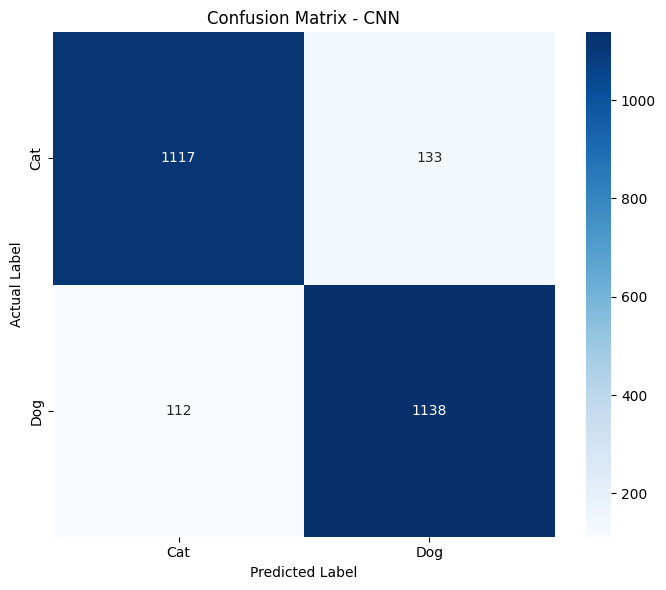

Confusion Matrix:
[[1117  133]
 [ 112 1138]]


In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Cat", "Dog"],
    yticklabels=["Cat", "Dog"]
)

plt.title("Confusion Matrix - CNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)


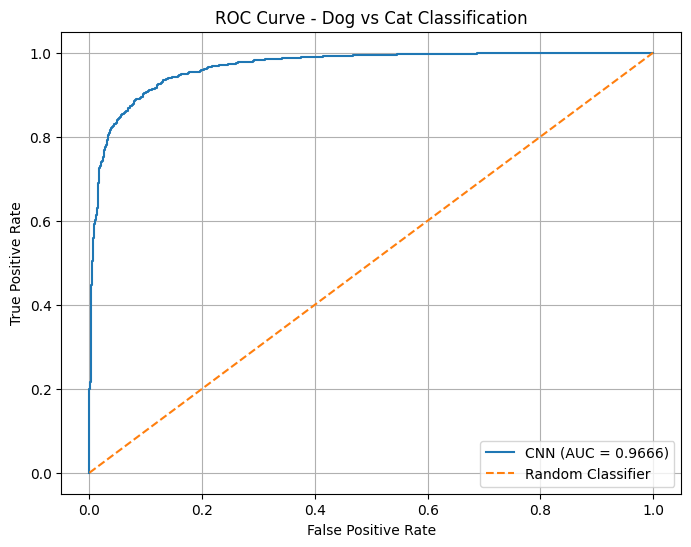

In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Dog vs Cat Classification")

plt.legend()
plt.grid(True)
plt.show()